  <span style="color: rgb(222, 158, 200);">Importazione del file e delle librerie</span>

In [6]:
import pandas as pd
df = pd.read_csv('books.csv')

 <span style="color: rgb(222, 158, 200);">PRIMA FASE: ESPLORAZIONE DEL DATAFRAME</span>
 <br />
 <p style="color: rgb(186, 95, 188);">1- Guardo la forma del dataset con shape. </p>
 <p style="color: rgb(186, 95, 188);">2- Stampo le informazioni come i null con .info come qunati null ci sono nelle colonne </p>
 <p style="color: rgb(186, 95, 188);">3- Stampo idati matematici con describe come la somma, il minimo, la media </p>
 <p style="color: rgb(186, 95, 188);">4- Stampo le prime 8 righe  </p>

In [7]:

print(df.shape) #forma del df. 2090 righe x 20 colonne
print('---------------------------------')

print(df.info())
#Il df presente valori nulli nelle colonne year_published,genre,section,total_copies, times_borrowed, last_borrowed_date,
#rating,ratings_count,price, language, page_count, dimensions_thickness   

print('---------------------------------')

print(df.describe())

print('---------------------------------')

print(df.head(8))


(2090, 20)
---------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2090 entries, 0 to 2089
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   catalog_position      2090 non-null   object 
 1   title                 2090 non-null   object 
 2   author                2090 non-null   object 
 3   year_published        2086 non-null   float64
 4   genre                 2039 non-null   object 
 5   section               2032 non-null   object 
 6   total_copies          2077 non-null   float64
 7   times_borrowed        2084 non-null   float64
 8   last_borrowed_date    2074 non-null   object 
 9   rating                1766 non-null   float64
 10  ratings_count         1762 non-null   float64
 11  price                 1879 non-null   float64
 12  language              2087 non-null   object 
 13  page_count            2085 non-null   float64
 14  dimensions_width      2090 

 <span style="color: rgb(222, 158, 200);">SECONDA FASE: PULIZIA DEL DATAFRAME</span>
 <br />
 <p style="color: rgb(186, 95, 188);">1- Tolgo i duplicati se ce ne sono. </p>
 <p style="color: rgb(186, 95, 188);">2- Tolgo le righe che hanno dei valori null dal dataset </p>
 <p style="color: rgb(186, 95, 188);">3- Controllo con .info se è andato tutto a buon fine </p>


In [8]:
df = df.drop_duplicates()

df = df.dropna()

print(df.info())


<class 'pandas.core.frame.DataFrame'>
Index: 1624 entries, 0 to 2077
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   catalog_position      1624 non-null   object 
 1   title                 1624 non-null   object 
 2   author                1624 non-null   object 
 3   year_published        1624 non-null   float64
 4   genre                 1624 non-null   object 
 5   section               1624 non-null   object 
 6   total_copies          1624 non-null   float64
 7   times_borrowed        1624 non-null   float64
 8   last_borrowed_date    1624 non-null   object 
 9   rating                1624 non-null   float64
 10  ratings_count         1624 non-null   float64
 11  price                 1624 non-null   float64
 12  language              1624 non-null   object 
 13  page_count            1624 non-null   float64
 14  dimensions_width      1624 non-null   float64
 15  dimensions_thickness  1624


<span style="color: rgb(222, 158, 200);">TERZA FASE: VISUALIZZAZIONE DATI </span>
 <br />
 <br />
 <p style="color: rgb(186, 95, 188);">Grafico a torta per mostrare i generi presi in prestito di più </p>


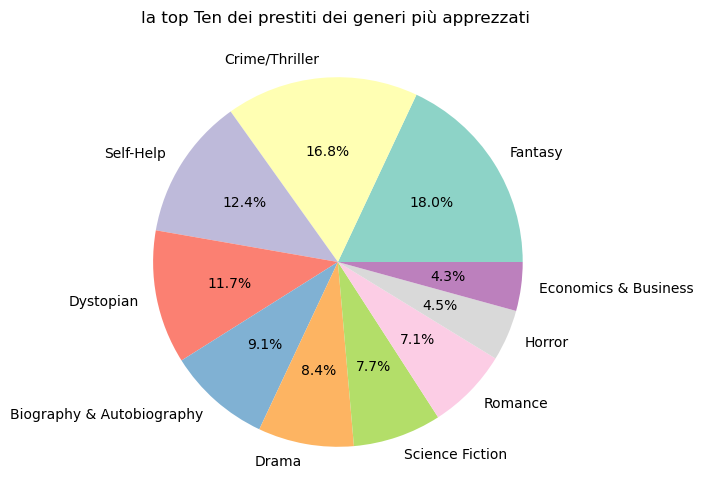

In [ ]:
import matplotlib.pyplot as plt


# raggruppo per genere e sommo per i prestiti 
prestiti_per_genere = df.groupby("genre")["times_borrowed"].sum()

# salvo in questa variabile sotto i generi con più prestiti attraverso il sort_values con ascending False che serve per ordinarli dal piu grande al piu piccolo. con l'head prendo i primi 10
prestiti_per_genere_top_ten = prestiti_per_genere.sort_values(ascending=False).head(10)

plt.figure(figsize=(6, 6))

plt.pie(
    prestiti_per_genere_top_ten,

# in labels c è l'index di prestiti_per_genere_top_ten che è il nome del genere
    labels=prestiti_per_genere_top_ten.index,

# mostra le percentuali con un decimale
    autopct="%1.1f%%", 
    
# setto la palette di colori pastello
    colors=plt.cm.Set3.colors,
)
plt.title("la top Ten dei prestiti dei generi più apprezzati ")
plt.show()

 <span style="color: rgb(186, 95, 188);">Da questo grafico a torta possiamo notare che i libri più apprezzati in quanto i più presi in prestito, sono quelli del genere fantasy, seguiti dai thriller, da self help ecc </span>

<H4 style="color: rgb(222, 158, 200);">Matplotlib: grafico a barre per libri piu prestati, autore e titolo</H4>

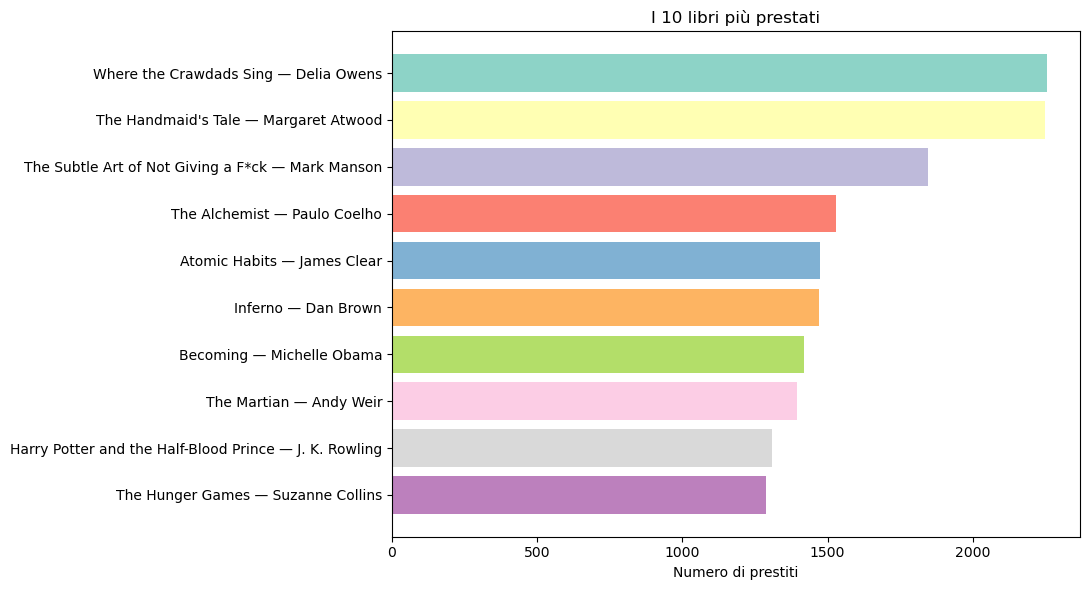

In [19]:

# i commenti sono da finire 

# con top_10 salviamo le prime 10 righe, ordinate per numero di prestiti dal piu grande al piu piccolo
top_10 = df.sort_values("times_borrowed", ascending=False).head(10)

# in etichette salviamo il titolo separato da un trattino e l'autore
etichette = top_10["title"] + " — " + top_10["author"]

fig, ax = plt.subplots(figsize=(11, 6))

# creiamo un grafico a barre orizzontale, che mette le etichette sull'asse verticale, top_10["times_borrowed"] prende i valori cioè è il numero di prestiti, e poi la nostra palette di colori pastello
ax.barh(etichette, top_10["times_borrowed"], color=plt.cm.Set3.colors)

# mette dal valore piu alto in alto al valore piu basso in basso
ax.invert_yaxis()
ax.set_xlabel("Numero di prestiti")
ax.set_title("I 10 libri più prestati")

# sistema i margini
fig.tight_layout()
plt.show()

 <span style="color: rgb(186, 95, 188);">Da questo grafico a barre orizzontali sono rappresentati i 10 titoli con più prestiti registrati. I primi due possiamo notare che sono i più popolari con più di 200 prestiti registrati </span>

<H4 style="color: rgb(222, 158, 200);">Matplotlib: grafico a barre dei mesi con più prestiti </H4>

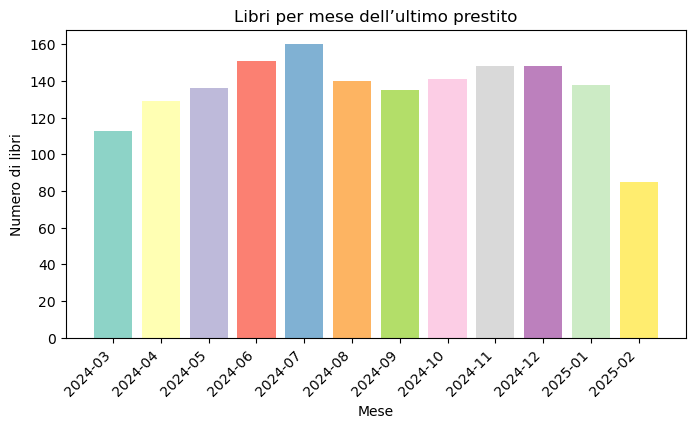

In [20]:
# qua last_borrowed_date è la colonna che rappresenta l'ultimo prestito registrato con formato mese giorno e anno
date = pd.to_datetime(df["last_borrowed_date"], format="%m/%d/%Y")

# .dt.to_period("M") tiene solo anno e mese. Poi conta il numero dei libri prestiti con value counts e infine li ordina in ordine cronologico
# libri_per_mese, contiene i mesi come indice e i conteggi come valori
libri_per_mese = date.dt.to_period("M").value_counts().sort_index()


plt.figure(figsize=(8, 4))
# qua libri_per_mese.index.astype(str) rappresenta come appaiono le etichette che abbiamo settato prima che rappresentano l'asse X, mentre libri_per_mese da l'altezza delle barre, e poi la nostra bella palette di colori pastello
plt.bar(libri_per_mese.index.astype(str), libri_per_mese, color=plt.cm.Set3.colors)
plt.title("Libri per mese dell’ultimo prestito")
plt.xlabel("Mese")
plt.ylabel("Numero di libri")
# sistemo la rotazione, in questo caso è 45 gradi verso destra
plt.xticks(rotation=45, ha="right")
plt.show()

 <span style="color: rgb(186, 95, 188);">Da questo grafico a barre orizzontali sono rappresentati i 10 titoli con più prestiti registrati. I primi due possiamo notare che sono i più popolari con più di 200 prestiti registrati </span>

 <H4 style="color: rgb(222, 158, 200);">MatplotLib: grafico interattivo di valutazioni e prestiti.</span>
 <br />
<span style="color: rgb(186, 95, 188);">I libri con i voti più alti sono anche quelli che vengono presi più in prestito?</span>

In [ ]:
import plotly.express as px


fig = px.scatter(
    df,
# mette la valutazione media sull'asse orizzontale
    x="rating",
# mette il numero di prestiti sull'asse verticale
    y="times_borrowed",
# assegna lo stesso colore ai libri della stessa lezione
    color="section",
# è il titolo che va in evidenza quando si passa il mouse sopra
    hover_name="title",
# gli altri dati che appaiono quando passi sopra il mouse
    hover_data=["author", "genre", "ratings_count"],
# palette di colori preimpostata con colori vivaci
    color_discrete_sequence=px.colors.qualitative.Vivid,
# le etichette che appaiono nell'hover
    labels={
        "rating": "Valutazione media",
        "times_borrowed": "Numero di prestiti",
        "section": "Sezione",
        "author": "Autore",
        "genre": "Genere",
        "ratings_count": "Numero di valutazioni",
    },
# il titolo del grafico
    title="Valutazioni e prestiti dei libri",
)
fig.show()

<span style="color: rgb(186, 95, 188);">